# 1- Encontre o(s) conjunto(s) com um suporte de 33% do conjunto de transações abaixo:
###T1 = tree, cup, paper
###T2 = book, tomato, pen
###T3 = pen, book, tree
###T4 = tomato, pen, cup
###T5 = tree, paper, book
###T6 = pen, book

In [1]:
#Usando a implementação do Apriori disponível na biblioteca mlxtend
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules
from mlxtend.preprocessing import TransactionEncoder
import pandas as pd

In [2]:
#Formato de lista de listas (cada lista simula uma transação)
tranactions =   [['tree','cup', 'paper'],
                 ['book','tomato','pen'],
                 ['pen','book','tree'],
                 ['tomato','pen','cup'],
                 ['tree','paper','book'],
                 ['pen','book']]

#so verificando o tam
total = len(tranactions)
total

#transformar em array boolean
te = TransactionEncoder()
encoded = te.fit(tranactions).transform(tranactions)
print(encoded)

#jogando em um dataframe para visualizar melhor
dfExemplo = pd.DataFrame(encoded, columns=te.columns_)
dfExemplo

# calcular conjunto com suporte de 33%
frequents = apriori(dfExemplo, min_support=0.33, use_colnames=True)
frequents

[[False  True  True False False  True]
 [ True False False  True  True False]
 [ True False False  True False  True]
 [False  True False  True  True False]
 [ True False  True False False  True]
 [ True False False  True False False]]


,support,itemsets
0,0.666667,(book)
1,0.333333,(cup)
2,0.333333,(paper)
3,0.666667,(pen)
4,0.333333,(tomato)
5,0.500000,(tree)
6,0.500000,"(pen, book)"
7,0.333333,"(book, tree)"
8,0.333333,"(paper, tree)"
9,0.333333,"(pen, tomato)"


##2- Dado o conjunto de transações:
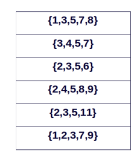

Gere regras para os conjuntos relativos à linha e coluna, nessa ordem, para todas as células da
matriz abaixo. Por exemplo, 2→3, 2→5 e 2→ 7 para a primeira linha da matriz.
Informar todas as regras com confiança mínima de 73%
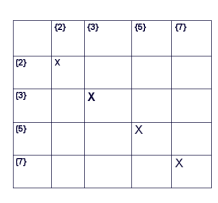

In [8]:
transactions = [ [1, 3, 5, 7, 8], [3, 4, 5, 7], [2, 3, 5, 6], [2, 4, 5, 8, 9], [2, 3, 5, 11], [1, 2, 3, 7, 9] ]

def gerar_regras(transactions, min_conf=0.73, regras_filtradas=None):
    regras_validas = []

    for trans in transactions:
        for i in trans:
            for j in trans:
                if i != j:
                    suporte_i = sum(i in t for t in transactions)
                    suporte_ij = sum(i in t and j in t for t in transactions)
                    confianca = suporte_ij / suporte_i if suporte_i else 0

                    if confianca >= min_conf:
                        regras_validas.append((i, j, round(confianca, 2)))

    regras_unicas = set(regras_validas)


    # Filtrar apenas as regras desejadas
    if regras_filtradas:
        regras_unicas = {r for r in regras_unicas if (r[0], r[1]) in regras_filtradas}

    return sorted(regras_unicas, key=lambda x: (-x[2], x[0], x[1]))

# Gera todas as regras
regras = gerar_regras(transactions, 0.73)

# Após gerar todas filtra de acordo com a matrix
# 2 -> 5 / 2 -> 3 / 2 -> 5
# O resto ou não está na matrix ou teve menos de 73% de confianca...
# Definição das regras específicas
regras_desejadas = {(2, 3), (2, 5), (3, 5)}

# Gera as regras expecificadas pela matrix do exercicio
regras = gerar_regras(transactions, 0.73, regras_desejadas)

print("Regras Aceitas da matrix especificada com mais de 73% de confiança:")
for antecedente, consequente, conf in regras:
    print(f"{antecedente} → {consequente} (confiança = {conf:.2f})")


Regras Aceitas da matrix especificada com mais de 73% de confiança:
3 → 5 (confiança = 0.80)
2 → 3 (confiança = 0.75)
2 → 5 (confiança = 0.75)


# Exercicio 3 -> supermercado.csv
- Utilize alguma implementação do Apriori, por exemplo, a da biblioteca mlxtend (python) ou do
pacote Arules (R).
- Utilize os dados sobre compras de supermercado “supermercado.csv”, disponível no moodle.
- Garanta que um conjunto de itens não contenha dois itens iguais.
- Execute o Apriori com as configurações: suporte mínimo = 0.001 e confiança = 0.25.
- Gere regras que contenham no consequente somente itens do tipo "bottled beer".
- Avaliação: o que você encontrou de interessante? Faça uma breve análise das regras e resultados
encontrados.


In [ ]:
# Carrega o CSV corretamente (uma transação por linha)
df = pd.read_csv("supermercado.csv", sep=';', header=None)

# Converte em lista de listas
transactions = df[0].apply(lambda x: x.strip().split(',')).tolist()

# Transforma em formato binário (0/1)
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

# Aplica Apriori
frequent_itemsets = apriori(df_encoded, min_support=0.001, use_colnames=True)

# Gera regras
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.25)

# Filtra as regras com consequente contendo 'bottled beer'
rules_beer = rules[rules['consequents'].apply(lambda x: 'bottled beer' in x)]

# Mostra as regras relevantes
print("Regras com 'bottled beer' como consequente:")
print(rules_beer[['antecedents', 'consequents', 'support', 'confidence', 'lift']])


Regras com 'bottled beer' como consequente:
                                           antecedents     consequents  \
27                                            (liquor)  (bottled beer)   
28                                    (red/blush wine)  (bottled beer)   
29                                               (tea)  (bottled beer)   
1017                            (herbs, bottled water)  (bottled beer)   
1022                              (oil, bottled water)  (bottled beer)   
1031                            (sugar, bottled water)  (bottled beer)   
1042                                  (onions, butter)  (bottled beer)   
1105                          (red/blush wine, liquor)  (bottled beer)   
1107                                    (liquor, soda)  (bottled beer)   
1126                (other vegetables, red/blush wine)  (bottled beer)   
1156                            (red/blush wine, soda)  (bottled beer)   
1158                      (roll products , whole milk)  (bottled bee

# Observações:
Bom a regra com maior confiança e maior lift indica que há uma forte associação entre entre vinhos e destilados e cerveja engarrafada, sendo mais propensos a levar cerveja quem compra vinho e destilados... Além disso é possivel notar que há algumas regras associando items de necessidade básica com cerveja o que sujere que compras de alimentos comuns como cebolas, leite frutas entre outros também compram cerveja.